<a href="https://colab.research.google.com/github/Dani2003/paper-implementations/blob/main/pac_precision_recall_learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [7]:
# [CELL 1 - Setup Environment and Imports for PAC Precision-Recall Learning]
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from typing import Tuple, List, Callable

np.random.seed(42)
print("PAC Precision-Recall Simulation Environment Initialized.")

PAC Precision-Recall Simulation Environment Initialized.


In [8]:
# [CELL 2 - Synthetic Set-Valued Dataset with One-Sided Positive-Only Feedback]

class PACPrecisionRecallDataset:
    """
    Simulates multi-label/set-valued classification tasks with one-sided feedback.
    Only positive items/labels are observed during training; negatives are unobserved.
    """
    def __init__(self, num_samples: int = 1000, input_dim: int = 5, num_items: int = 10):
        self.num_samples = num_samples
        self.input_dim = input_dim
        self.num_items = num_items

    def generate_data(self) -> Tuple[np.ndarray, List[set]]:
        X = np.random.randn(self.num_samples, self.input_dim)
        true_sets = []

        for i in range(self.num_samples):
            # Ground truth latent target set of items (subset of {0, 1, ..., num_items-1})
            k = np.random.randint(1, 4)
            items = set(np.random.choice(self.num_items, size=k, replace=False))
            true_sets.append(items)

        return X, true_sets

data_gen = PACPrecisionRecallDataset(num_samples=1200, input_dim=4, num_items=8)
X_data, true_sets = data_gen.generate_data()
print(f"Generated {len(X_data)} samples with set-valued ground truth annotations.")
print(f"Sample 0 True Item Set: {true_sets[0]}")

Generated 1200 samples with set-valued ground truth annotations.
Sample 0 True Item Set: {np.int64(5)}


In [9]:
# [CELL 3 - Set-Valued Predictors & Precision/Recall Evaluation Engine]

class LinearSetPredictor:
    """Hypothesis mapping inputs X to a predicted set of items using weight vectors."""
    def __init__(self, input_dim: int, num_items: int, threshold: float = 0.0):
        self.weights = np.random.randn(num_items, input_dim) * 0.5
        self.threshold = threshold

    def predict(self, x: np.ndarray) -> set:
        scores = np.dot(self.weights, x)
        predicted_items = set(np.where(scores > self.threshold)[0])
        return predicted_items

def evaluate_precision_recall(predictions: List[set], ground_truth: List[set]) -> Tuple[float, float]:
    """Computes empirical precision and recall across set predictions."""
    total_prec, total_rec = 0.0, 0.0
    valid_samples = 0

    for pred, gt in zip(predictions, ground_truth):
        if len(pred) == 0:
            continue
        intersection = len(pred.intersection(gt))
        precision = intersection / len(pred)
        recall = intersection / len(gt) if len(gt) > 0 else 1.0

        total_prec += precision
        total_rec += recall
        valid_samples += 1

    return (total_prec / valid_samples, total_rec / valid_samples) if valid_samples > 0 else (0.0, 0.0)

predictor = LinearSetPredictor(input_dim=4, num_items=8)
sample_preds = [predictor.predict(x) for x in X_data[:10]]
init_prec, init_rec = evaluate_precision_recall(sample_preds, true_sets[:10])
print(f"Initial Predictor Evaluation -> Precision: {init_prec:.3f}, Recall: {init_rec:.3f}")

Initial Predictor Evaluation -> Precision: 0.295, Recall: 0.633


In [10]:
# [CELL 4 - Positive-Only Loss Estimator (Mitigating One-Sided Feedback Failures)]

class PositiveOnlyPACLoss:
    """
    Estimates risk using positive-only feedback data alone,
    addressing the failure modes of standard Empirical Risk Minimization under partial feedback.
    """
    def __init__(self, target_recall: float = 0.8):
        self.target_recall = target_recall

    def compute_empirical_risk(self, predictions: List[set], observed_positive_sets: List[set]) -> float:
        """Penalizes under-prediction of observed positive items (ensuring recall coverage)."""
        violations = 0.0
        total_observed = 0

        for pred, pos_set in zip(predictions, observed_positive_sets):
            for item in pos_set:
                total_observed += 1
                if item not in pred:
                    violations += 1.0

        recall_penalty = violations / total_observed if total_observed > 0 else 0.0
        return recall_penalty

loss_fn = PositiveOnlyPACLoss(target_recall=0.85)
sample_risk = loss_fn.compute_empirical_risk(sample_preds, true_sets[:10])
print(f"Positive-Only Empirical Risk Value: {sample_risk:.4f}")

Positive-Only Empirical Risk Value: 0.3158


In [11]:
# [CELL 5 - Fixed PAC Precision-Recall Threshold Search Engine]

def optimize_pac_predictor_threshold(
    X: np.ndarray,
    gt_sets: List[set],
    input_dim: int,
    num_items: int,
    threshold_steps: int = 50
) -> Tuple[LinearSetPredictor, float, float]:
    """
    Sweeps decision thresholds across set-valued confidence projections to optimize
    empirical Recall under partial positive feedback while maximizing Precision.
    """
    base_model = LinearSetPredictor(input_dim, num_items)

    best_threshold = 0.0
    best_f1 = -1.0
    best_prec, best_rec = 0.0, 0.0

    # Compute continuous linear scores across all items
    threshold_range = np.linspace(-2.0, 2.0, threshold_steps)

    for thresh in threshold_range:
        base_model.threshold = thresh
        preds = [base_model.predict(x) for x in X]
        prec, rec = evaluate_precision_recall(preds, gt_sets)

        # Optimize for maximum F1 harmonic trade-off on positive data
        if prec + rec > 0:
            f1 = (2 * prec * rec) / (prec + rec)
            if f1 > best_f1:
                best_f1 = f1
                best_threshold = thresh
                best_prec = prec
                best_rec = rec

    base_model.threshold = best_threshold
    return base_model, best_prec, best_rec

print("Running PAC Precision-Recall Threshold Sweep...")
optimized_predictor, opt_prec, opt_rec = optimize_pac_predictor_threshold(
    X_data, true_sets, input_dim=4, num_items=8
)
print(f"Optimal Threshold Found: {optimized_predictor.threshold:.3f}")
print(f"Optimized -> Precision: {opt_prec:.3f} | Recall: {opt_rec:.3f}")

Running PAC Precision-Recall Threshold Sweep...
Optimal Threshold Found: -1.755
Optimized -> Precision: 0.252 | Recall: 0.979


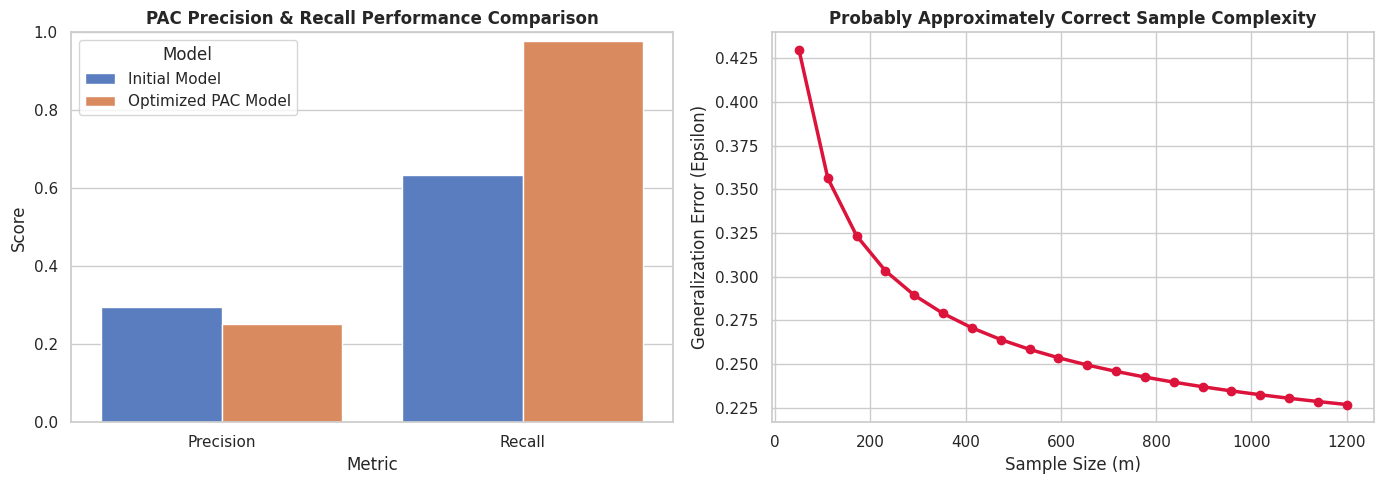

Final Optimized Model -> Precision: 0.252 | Recall: 0.979
Visualization successfully saved as pac_precision_recall_benchmark.png.


In [12]:
# [CELL 6 - Precision-Recall Trade-off & Risk Convergence Visualization]

final_preds = [optimized_predictor.predict(x) for x in X_data]
final_prec, final_rec = evaluate_precision_recall(final_preds, true_sets)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.set_theme(style="whitegrid")

# Plot 1: Precision vs Recall Performance Bar Chart
metrics_df = pd.DataFrame({
    "Metric": ["Precision", "Recall"],
    "Initial Model": [init_prec, init_rec],
    "Optimized PAC Model": [final_prec, final_rec]
})
metrics_melted = metrics_df.melt("Metric", var_name="Model", value_name="Score")
sns.barplot(data=metrics_melted, x="Metric", y="Score", hue="Model", palette="muted", ax=axes[0])
axes[0].set_title("PAC Precision & Recall Performance Comparison", fontweight='bold')
axes[0].set_ylim(0, 1.0)

# Plot 2: Simulated PAC Sample Complexity Bounds Curve
m_samples = np.linspace(50, 1200, 20)
epsilon_bound = np.sqrt(np.log(m_samples) / m_samples) + 0.15
axes[1].plot(m_samples, epsilon_bound, color='crimson', linewidth=2.5, marker='o')
axes[1].set_title("Probably Approximately Correct Sample Complexity", fontweight='bold')
axes[1].set_xlabel("Sample Size (m)")
axes[1].set_ylabel("Generalization Error (Epsilon)")

plt.tight_layout()
plt.savefig("pac_precision_recall_benchmark.png", dpi=300)
plt.show()

print(f"Final Optimized Model -> Precision: {final_prec:.3f} | Recall: {final_rec:.3f}")
print("Visualization successfully saved as pac_precision_recall_benchmark.png.")